# 00 — Data Audit | Telecom Customer Churn

**Mục tiêu:** xác minh cấu trúc, nhãn, dữ liệu thiếu, tính hợp lệ và các rủi ro trước khi thực hiện EDA / huấn luyện 4 mô hình.  
**Nguồn:** hai CSV gốc trong `data/raw/`. Không chỉnh sửa dữ liệu gốc.

**Câu hỏi nghiên cứu:** Dataset có phù hợp để dự đoán churn không? Có những rủi ro nào có thể khiến kết quả thực nghiệm sai lệch?

> Quy ước: `Churn = Yes` là lớp dương (1). File prediction không có nhãn, không dùng để tính metrics. Các kết luận về thời gian ghi nhận và tính đại diện cần xác minh với nguồn dữ liệu gốc.

## 1. Khởi tạo và tải dữ liệu

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
TARGET = 'Churn'
ID = 'CustomerID'
REVIEW_FOR_LEAKAGE = ['RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']
def load_labeled():
    return pd.read_csv(ROOT / 'data/raw/Telecom Data.csv')
def load_unlabeled():
    return pd.read_csv(ROOT / 'data/raw/Telecom - Prediction Data.csv')

train = load_labeled()
predict = load_unlabeled()
print("Training:", train.shape, "| Prediction:", predict.shape)
display(train.head(3))

Training: (51047, 58) | Prediction: (20000, 58)


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes


## 2. Kiểm tra schema, ID, target và dữ liệu trùng lặp

In [2]:
schema = pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "prediction_dtype": predict.dtypes.astype(str),
    "train_non_null": train.notna().sum(),
    "prediction_non_null": predict.notna().sum(),
    "train_unique": train.nunique(dropna=True),
    "prediction_unique": predict.nunique(dropna=True),
})
print("Cột chỉ có ở train:", sorted(set(train.columns) - set(predict.columns)))
print("Cột chỉ có ở prediction:", sorted(set(predict.columns) - set(train.columns)))
print("Trùng hàng train/prediction:", train.duplicated().sum(), predict.duplicated().sum())
print("Trùng CustomerID train/prediction:", train[ID].duplicated().sum(), predict[ID].duplicated().sum())
print("CustomerID giao nhau:", len(set(train[ID]) & set(predict[ID])))
print("Target train:", train[TARGET].value_counts(dropna=False).to_dict())
print("Target prediction:", predict[TARGET].value_counts(dropna=False).to_dict())
display(schema)

Cột chỉ có ở train: []
Cột chỉ có ở prediction: []
Trùng hàng train/prediction: 0 0
Trùng CustomerID train/prediction: 0 0
CustomerID giao nhau: 0
Target train: {'No': 36336, 'Yes': 14711}
Target prediction: {nan: 20000}


,train_dtype,prediction_dtype,train_non_null,prediction_non_null,train_unique,prediction_unique
CustomerID,int64,int64,51047,20000,51047,20000
Churn,str,float64,51047,0,2,0
MonthlyRevenue,float64,float64,50891,19940,12665,8383
MonthlyMinutes,float64,float64,50891,19940,2719,2216
TotalRecurringCharge,float64,float64,50891,19940,214,182
DirectorAssistedCalls,float64,float64,50891,19940,146,112
OverageMinutes,float64,float64,50891,19940,746,566
RoamingCalls,float64,float64,50891,19940,530,366
PercChangeMinutes,float64,float64,50680,19865,2262,1688
PercChangeRevenues,float64,float64,50680,19865,2899,2130


**Điều kiện kiểm tra:** không được có nhãn trống ở tập huấn luyện; file prediction phải chưa có nhãn. `CustomerID` là định danh, không đưa vào features. Việc không trùng ID không tự chứng minh hai tập độc lập theo thời gian hoặc nguồn thu thập.

In [3]:
assert train[TARGET].notna().all(), "Training target bị thiếu"
assert predict[TARGET].isna().all(), "Prediction có nhãn ngoài dự kiến"
assert set(train[TARGET].unique()) == {"Yes", "No"}, "Nhãn ngoài dự kiến"
assert set(train.columns) == set(predict.columns), "Schema không khớp"
assert train[ID].is_unique and predict[ID].is_unique, "CustomerID trùng trong file"
print("✓ Kiểm tra cơ bản đạt")

✓ Kiểm tra cơ bản đạt


## 3. Phân bố nhãn Churn

,Churn,count,percent
0,No,36336,71.18
1,Yes,14711,28.82


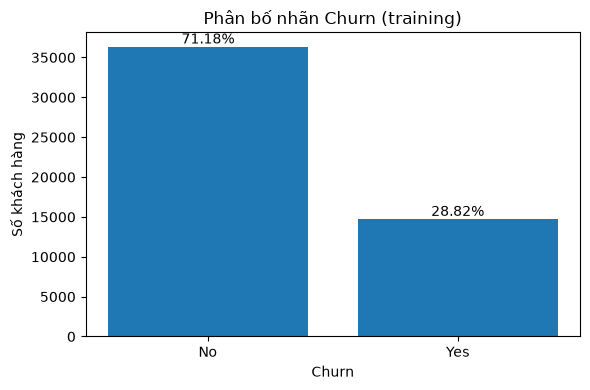

Majority-class accuracy (tham chiếu): 0.7118


In [4]:
target_summary = train[TARGET].value_counts().rename_axis("Churn").reset_index(name="count")
target_summary["percent"] = (target_summary["count"] / len(train) * 100).round(2)
display(target_summary)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(target_summary["Churn"], target_summary["count"])
ax.set(title="Phân bố nhãn Churn (training)", xlabel="Churn", ylabel="Số khách hàng")
for i, r in target_summary.iterrows():
    ax.text(i, r["count"], f'{r["percent"]:.2f}%', ha="center", va="bottom")
plt.tight_layout()
plt.show()
print("Majority-class accuracy (tham chiếu):", round(train[TARGET].value_counts(normalize=True).max(), 4))

**Nhận xét:** dữ liệu có mất cân bằng mức vừa phải. Một mô hình luôn đoán `No` đã có accuracy xấp xỉ 71,18%, vì vậy không thể dùng Accuracy làm chỉ số duy nhất. Ưu tiên thêm Recall, Precision, F1, PR-AUC và ROC-AUC.

## 4. Missing values và giá trị placeholder

In [5]:
def missing_table(df):
    out = df.isna().sum().rename("missing_count").to_frame()
    out["missing_pct"] = (out["missing_count"] / len(df) * 100).round(2)
    return out[out["missing_count"] > 0].sort_values("missing_count", ascending=False)

print("TRAIN — thiếu thực tế:")
display(missing_table(train))
print("PREDICTION — thiếu thực tế:")
display(missing_table(predict))

# Những chuỗi như Unknown không tự được pandas nhận diện là NaN.
placeholders = ["Unknown", "unknown", "?", "NA", "N/A", "Not Available", ""]
placeholder_rows = []
for name, df in [("train", train), ("prediction", predict)]:
    for col in df.select_dtypes(include="object").columns:
        s = df[col].astype("string").str.strip()
        n = int(s.isin(placeholders).sum())
        if n:
            placeholder_rows.append({"dataset": name, "column": col, "placeholder_count": n,
                                     "placeholder_pct": round(n / len(df) * 100, 2)})
placeholder_df = pd.DataFrame(placeholder_rows)
display(placeholder_df.sort_values(["dataset", "placeholder_count"], ascending=[True, False]))

TRAIN — thiếu thực tế:


,missing_count,missing_pct
AgeHH2,909,1.78
AgeHH1,909,1.78
PercChangeRevenues,367,0.72
PercChangeMinutes,367,0.72
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31
RoamingCalls,156,0.31
OverageMinutes,156,0.31
DirectorAssistedCalls,156,0.31
TotalRecurringCharge,156,0.31


PREDICTION — thiếu thực tế:


,missing_count,missing_pct
Churn,20000,100.00
AgeHH1,335,1.68
AgeHH2,335,1.68
PercChangeMinutes,135,0.68
PercChangeRevenues,135,0.68
TotalRecurringCharge,60,0.30
MonthlyRevenue,60,0.30
MonthlyMinutes,60,0.30
RoamingCalls,60,0.30
OverageMinutes,60,0.30


C:\Users\X1_Extreme\AppData\Local\Temp\ipykernel_15364\914631492.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\X1_Extreme\AppData\Local\Temp\ipykernel_15364\914631492.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/use

,dataset,column,placeholder_count,placeholder_pct
4,prediction,HandsetPrice,11267,56.34
5,prediction,MaritalStatus,7640,38.20
3,prediction,Homeownership,6522,32.61
1,train,HandsetPrice,28982,56.78
2,train,MaritalStatus,19700,38.59
0,train,Homeownership,17060,33.42


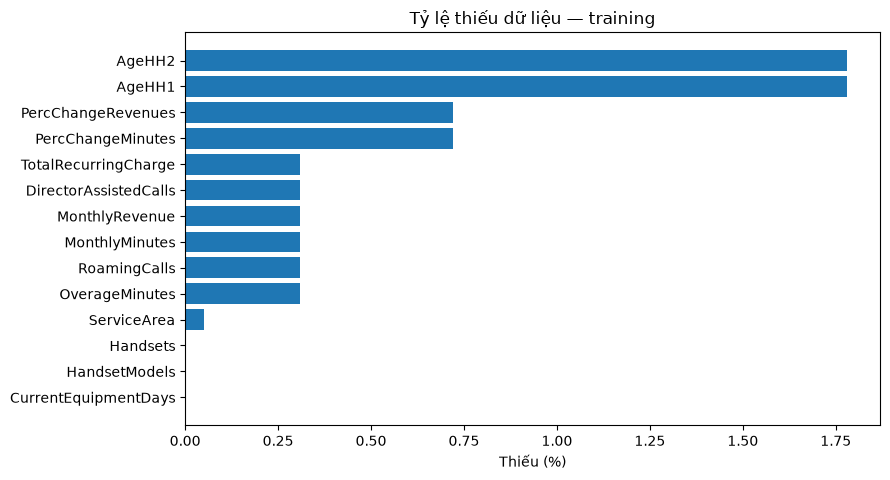

In [6]:
missing = missing_table(train).head(15).sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(9, max(3, 0.35 * len(missing))))
ax.barh(missing.index, missing["missing_pct"])
ax.set(title="Tỷ lệ thiếu dữ liệu — training", xlabel="Thiếu (%)")
plt.tight_layout()
plt.show()

**Cảnh báo:** `HandsetPrice` có nhiều giá trị chuỗi `Unknown`, cần xử lý như missing/nhóm chưa biết theo thiết kế pipeline. Không được điền missing bằng thống kê tính từ cả train và test; imputer phải `fit` trên training fold.

## 5. Kiểm tra phân bố, giá trị bất thường và cột ít biến thiên

In [7]:
numeric_cols = train.drop(columns=[ID]).select_dtypes(include="number").columns
summary_numeric = train[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary_numeric["zero_pct"] = (train[numeric_cols].eq(0).mean() * 100).round(2)
display(summary_numeric.sort_values("zero_pct", ascending=False).head(20))

low_cardinality = train.nunique(dropna=False).sort_values()
print("Cột chỉ có 1 giá trị:", low_cardinality[low_cardinality == 1].index.tolist())
print("Cột có <= 3 giá trị:")
display(low_cardinality[low_cardinality <= 3])

cat_cardinality = train.select_dtypes(include="object").nunique(dropna=True).sort_values(ascending=False)
print("Categorical cardinality cao nhất:")
display(cat_cardinality.head(12))

,count,mean,std,min,1%,25%,50%,75%,99%,max,zero_pct
CallForwardingCalls,51047.0,0.012277,0.594168,0.0,0.000,0.0,0.00,0.00,0.000,81.30,99.54
RetentionOffersAccepted,51047.0,0.018277,0.142458,0.0,0.000,0.0,0.00,0.00,1.000,3.00,98.27
RetentionCalls,51047.0,0.037201,0.206483,0.0,0.000,0.0,0.00,0.00,1.000,4.00,96.58
AdjustmentsToCreditRating,51047.0,0.053911,0.383147,0.0,0.000,0.0,0.00,0.00,1.000,25.00,96.40
ReferralsMadeBySubscriber,51047.0,0.052070,0.307592,0.0,0.000,0.0,0.00,0.00,1.000,35.00,95.33
ThreewayCalls,51047.0,0.298838,1.168277,0.0,0.000,0.0,0.00,0.30,4.000,66.00,72.74
RoamingCalls,50891.0,1.236244,9.818294,0.0,0.000,0.0,0.00,0.30,21.500,1112.40,68.46
CustomerCareCalls,51047.0,1.868999,5.096138,0.0,0.000,0.0,0.00,1.70,21.000,327.30,54.89
AgeHH2,50138.0,21.144142,23.931368,0.0,0.000,0.0,0.00,42.00,76.000,99.00,51.10
CallWaitingCalls,51047.0,1.840504,5.585129,0.0,0.000,0.0,0.30,1.30,23.000,212.70,49.03


Cột chỉ có 1 giá trị: []
Cột có <= 3 giá trị:


Churn                      2
MadeCallToRetentionTeam    2
NewCellphoneUser           2
NotNewCellphoneUser        2
HasCreditCard              2
OwnsComputer               2
NonUSTravel                2
OptOutMailings             2
RespondsToMailOffers       2
BuysViaMailOrder           2
Homeownership              2
RVOwner                    2
TruckOwner                 2
HandsetWebCapable          2
HandsetRefurbished         2
ChildrenInHH               2
OwnsMotorcycle             2
MaritalStatus              3
dtype: int64

Categorical cardinality cao nhất:


C:\Users\X1_Extreme\AppData\Local\Temp\ipykernel_15364\1352553032.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cardinality = train.select_dtypes(include="object").nunique(dropna=True).sort_values(ascending=False)


ServiceArea           747
HandsetPrice           16
Occupation              8
CreditRating            7
PrizmCode               4
MaritalStatus           3
Churn                   2
RVOwner                 2
TruckOwner              2
HandsetWebCapable       2
HandsetRefurbished      2
ChildrenInHH            2
dtype: int64

**Lưu ý:** không mặc định coi các giá trị 0 hoặc outlier là lỗi. Ví dụ, `RetentionCalls = 0` có thể là một hành vi hợp lệ. Phải phân biệt ngoại lệ hợp lệ và sai dữ liệu trước khi xử lý.

## 6. Khảo sát train vs prediction (không dùng nhãn)

In [8]:
shared_numeric = [x for x in numeric_cols if x in predict.columns]
shift_rows = []
for col in shared_numeric:
    a, b = train[col].dropna(), predict[col].dropna()
    if len(a) and len(b):
        shift_rows.append({"feature": col, "train_mean": a.mean(), "predict_mean": b.mean(),
                           "train_missing_pct": train[col].isna().mean() * 100,
                           "predict_missing_pct": predict[col].isna().mean() * 100})
shift_df = pd.DataFrame(shift_rows)
shift_df["abs_mean_diff"] = (shift_df["train_mean"] - shift_df["predict_mean"]).abs()
display(shift_df.sort_values("abs_mean_diff", ascending=False).head(12))

,feature,train_mean,predict_mean,train_missing_pct,predict_missing_pct,abs_mean_diff
6,PercChangeMinutes,-11.547908,-9.052806,0.718945,0.675,2.495102
26,CurrentEquipmentDays,380.545841,379.550450,0.001959,0.000,0.995391
17,OffPeakCallsInOut,67.650790,68.245900,0.000000,0.000,0.595110
13,ReceivedCalls,114.800121,115.280595,0.000000,0.000,0.480474
1,MonthlyMinutes,525.653416,525.912136,0.305601,0.300,0.258720
10,UnansweredCalls,28.288981,28.526345,0.000000,0.000,0.237364
4,OverageMinutes,40.027785,40.240722,0.305601,0.300,0.212937
27,AgeHH1,31.338127,31.469413,1.780712,1.675,0.131286
2,TotalRecurringCharge,46.830088,46.946640,0.305601,0.300,0.116552
16,PeakCallsInOut,90.549515,90.661230,0.000000,0.000,0.111715


**Giới hạn:** chênh lệch trung bình chỉ là tín hiệu để khảo sát, không phải kiểm định distribution shift. Các thí nghiệm chính phải đánh giá trên hold-out có nhãn, không dùng file prediction làm test set.

## 7. Kiểm tra rủi ro data leakage và quyết định đặc trưng

In [9]:
risk_register = pd.DataFrame([
    {"feature": ID, "risk": "Định danh có thể học thuộc khách hàng", "action": "Loại khỏi features"},
    {"feature": "RetentionCalls", "risk": "Có thể phát sinh sau thời điểm dự đoán", "action": "Tạm loại; xác minh thời điểm ghi nhận"},
    {"feature": "RetentionOffersAccepted", "risk": "Có thể phát sinh sau thời điểm dự đoán", "action": "Tạm loại; xác minh thời điểm ghi nhận"},
    {"feature": "MadeCallToRetentionTeam", "risk": "Có thể phát sinh sau thời điểm dự đoán", "action": "Tạm loại; xác minh thời điểm ghi nhận"},
    {"feature": "ServiceArea", "risk": "Cardinality cao, dễ overfit / nở one-hot", "action": "Kiểm tra trước khi encoding"},
    {"feature": "HandsetPrice", "risk": "Unknown là placeholder và giá trị số dạng text", "action": "Chuẩn hóa trong pipeline"},
])
display(risk_register)
print("Feature candidates sau khi loại ID, target và 3 retention columns:",
      len([c for c in train.columns if c not in [ID, TARGET, *REVIEW_FOR_LEAKAGE]]))

,feature,risk,action
0,CustomerID,Định danh có thể học thuộc khách hàng,Loại khỏi features
1,RetentionCalls,Có thể phát sinh sau thời điểm dự đoán,Tạm loại; xác minh thời điểm ghi nhận
2,RetentionOffersAccepted,Có thể phát sinh sau thời điểm dự đoán,Tạm loại; xác minh thời điểm ghi nhận
3,MadeCallToRetentionTeam,Có thể phát sinh sau thời điểm dự đoán,Tạm loại; xác minh thời điểm ghi nhận
4,ServiceArea,"Cardinality cao, dễ overfit / nở one-hot",Kiểm tra trước khi encoding
5,HandsetPrice,Unknown là placeholder và giá trị số dạng text,Chuẩn hóa trong pipeline


Feature candidates sau khi loại ID, target và 3 retention columns: 53


**Không kết luận chắc chắn leakage chỉ từ tên cột.** Cần tài liệu nguồn để xác minh thời điểm đo đặc trưng so với thời điểm churn. Trong baseline, tạm loại 3 biến retention để tránh rủi ro. Có thể thiết kế thí nghiệm độ nhạy *có/không có nhóm retention* sau khi xác minh ngữ nghĩa và thời gian ghi nhận.

## 8. Tổng kết audit và checklist chuyển sang EDA

In [10]:
audit_summary = pd.DataFrame([
    {"check": "Số dòng training", "result": len(train)},
    {"check": "Số dòng prediction", "result": len(predict)},
    {"check": "Số cột mỗi file", "result": train.shape[1]},
    {"check": "Số nhãn Churn=Yes", "result": int((train[TARGET] == "Yes").sum())},
    {"check": "Tỷ lệ churn (%)", "result": round((train[TARGET] == "Yes").mean() * 100, 2)},
    {"check": "Dòng trùng training", "result": int(train.duplicated().sum())},
    {"check": "Cột có missing (không tính Churn prediction)", "result": len(missing_table(train))},
    {"check": "Số feature baseline dự kiến", "result": len(train.columns) - 5},
])
display(audit_summary)

print("NEXT: 01_eda.ipynb → thống nhất split → preprocessing pipeline → 4 baseline models")

,check,result
0,Số dòng training,51047.00
1,Số dòng prediction,20000.00
2,Số cột mỗi file,58.00
3,Số nhãn Churn=Yes,14711.00
4,Tỷ lệ churn (%),28.82
5,Dòng trùng training,0.00
6,Cột có missing (không tính Churn prediction),14.00
7,Số feature baseline dự kiến,53.00


NEXT: 01_eda.ipynb → thống nhất split → preprocessing pipeline → 4 baseline models


### Kết luận dùng trong báo cáo (cần hiệu chỉnh theo kết quả chạy)

- Bộ dữ liệu huấn luyện gồm **51.047** bản ghi và **58** cột; bộ dữ liệu dự đoán gồm **20.000** bản ghi với nhãn `Churn` để trống.
- Nhãn `Yes` chiếm khoảng **28,82%**, cho thấy mức mất cân bằng cần xem xét trong thiết kế đánh giá.
- Có dữ liệu thiếu ở một số biến và placeholder `Unknown` ở `HandsetPrice`.
- Nhóm sẽ loại `CustomerID` và tạm loại ba biến liên quan retention khỏi baseline, chờ xác minh thời điểm thu thập.
- **Chưa thể khẳng định dữ liệu được thu thập gần đây hoặc là dữ liệu thực tế** chỉ từ hai file CSV. Cần bổ sung thông tin nguồn gốc trước khi nộp báo cáo.

**Bước tiếp theo:** EDA (phân phối các feature, liên hệ với churn, nhóm đặc trưng, tương quan) và định nghĩa pipeline chung. Không chỉnh sửa trực tiếp CSV gốc.